# **Analisi di Wikipedia**
PROFESSION AI--Nicola Giusti

## Descrizione del Progetto
L'obiettivo principale è comprendere meglio il vasto patrimonio di contenuti informativi offerti da Wikipedia e sviluppare un sistema di classificazione automatica che consenta di categorizzare efficacemente i nuovi articoli futuri.

## Obiettivi
1. Analisi Descrittiva dei Contenuti:

Il primo obiettivo del progetto è condurre un'analisi esplorativa dei dati (EDA) per capire le caratteristiche dei contenuti di Wikipedia suddivisi in diverse categorie tematiche, come ad esempio: - Cultura, Economia, Medicina, Tecnologia, Politica, Scienza, e altre.

L'analisi esplorativa prevede:
- Il conteggio degli articoli presenti per ogni categoria.
- Il numero medio di parole per articolo.
- La lunghezza dell'articolo più lungo e di quello più corto per ciascuna categoria.
- La creazione di nuvole di parole rappresentative per ogni categoria, per identificare i termini più frequenti e rilevanti.

2. Sviluppo di un Classificatore Automatico:

Il secondo obiettivo è creare un modello di machine learning capace di classificare automaticamente gli articoli in base alla loro categoria.
Il sistema di classificazione verrà addestrato utilizzando dati di testo presenti nelle seguenti colonne del dataset:
- Sommario (summary): Introduzione breve dell'articolo.
- Testo Completo (documents): Contenuto completo dell'articolo.

## Workflow del Progetto
### Caricamento dei Dati
Il dataset è salvato su S3 e reperibile al seguente link: https://proai-datasets.s3.eu-west-3.amazonaws.com/wikipedia.csv

Per poter caricare il dataframe e trasformarlo in una table basta eseguire su Notebook Databricks le seguenti celle:

```sql
CREATE CATALOG IF NOT EXISTS my_catalog;
CREATE SCHEMA  IF NOT EXISTS my_catalog.raw;
CREATE VOLUME  IF NOT EXISTS my_catalog.raw.datasets
```

```sh
mkdir -p /Volumes/my_catalog/raw/datasets
curl -L "https://proai-datasets.s3.eu-west-3.amazonaws.com/wikipedia.csv" -o /Volumes/my_catalog/raw/datasets/wikipedia.csv
path = "/Volumes/my_catalog/raw/datasets/wikipedia.csv"
df = spark.read.csv(path, header=True, inferSchema=True)
```


In [ ]:
# codice standard per evitare waning
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [ ]:
# ==============================================================================
# 1. INSTALLAZIONE DELLE DIPENDENZE
# ==============================================================================
!pip install pyspark wordcloud -q

# ==============================================================================
# 2. LIBRERIE CORE PYTHON e GESTIONE MEMORIA
# ==============================================================================
import gc
import os
import numpy as np
import pandas as pd

# ==============================================================================
# 3. SPARK CORE, SQL FUNCTIONS, WINDOW FUNCTIONS
# ==============================================================================
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import ArrayType, IntegerType, StringType
from pyspark.sql.window import Window

# ==============================================================================
# 4. LIBRERIE DI VISUALIZZAZIONE (Per i grafici dell'EDA e le Nuvole di Parole)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import math

# ==============================================================================
# 5. PYSPARK ML - NLP PIPELINE, FEATURE ENGINEERING
# ==============================================================================
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (
    HashingTF,
    IDF,
    StopWordsRemover,
    StringIndexer,
    Tokenizer,
    VectorAssembler,
    RegexTokenizer,
    NGram,
)


# ==============================================================================
# 6. PYSPARK MLIB - MODELLAZIONE, IPERPARAMETRI E VALUTAZIONE
# ==============================================================================
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.classification import MultilayerPerceptronClassifier
from sklearn.metrics import classification_report, confusion_matrix
from pyspark.ml.feature import IndexToString

In [ ]:
# Creazione della sessione Spark (che gestisce anche il motore SQL)
spark = SparkSession.builder \
    .appName("WikipediaAnalysis") \
    .config("spark.driver.memory", "8g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .getOrCreate()

### ABSTRACT: Classificazione Multiclasse di Articoli Wikipedia tramite Apache Spark

L'architettura del progetto si è articolata attraverso cinque punti nodali:

1- Data Ingestion e Feature Engineering: Il dataset, composto da testi etichettati, è stato affrontato fondendo sistematicamente la sezione introduttiva (summary) e il corpo principale (documents) di ogni articolo. Questa operazione ha massimizzato la densità semantica del testo in ingresso, fornendo al modello sia la sintesi concettuale che la profondità del contesto.

2- Pipeline di Preprocessing Distribuita: Il testo grezzo è stato sottoposto a una catena di montaggio sequenziale composta da pulizia tramite espressioni regolari (RegexTokenizer), rimozione di stop-words standard e personalizzate, vettorizzazione (HashingTF impostato a 10.000 feature) e pesatura statistica tramite IDF (Inverse Document Frequency).

3-Modellazione Avanzata e Deep Learning: È stato condotto uno studio comparativo architettando tre differenti approcci algoritmici. Al modello base (Logistic Regression) sviluppato con due approcci, è stata affiancata una rete neurale spark MLP (Multilayer Perceptron Classifier) a quattro livelli [10.000, 64, 32, 15], ottimizzata con mini-batch da 128 record su ambiente containerizzato/Colab.

3- Analisi delle Performance: Il modello selezionato ha raggiunto un'accuratezza macro complessiva del 93%. L'analisi critica condotta tramite classification report ha evidenziato le eccellenze del modello su categorie specifiche (esempio politics al 99%) e ha permesso di mappare i margini dell'MLP, legati alla naturale sovrapposizione semantica tra domini affini (per esempio il binomio medicine/research e finance/economics).

5- Industrializzazione: Il modello è stato congelato e serializzato su disco tramite il costrutto PipelineModel di Spark, garantendo la portabilità del modello e un caricamento istantaneo per future fasi di inferenza senza la necessità di riaddestramento.

## DATASET
Nel caricamento del dataset utilizziamo spark invece che pandas per evitare che la RAM si saturi con un eventuale dataset troppo grosso.

Aggiungiamo l'opzione *multiline=True* per evitare che spark legga gli a capo come cambio articolo.

In [ ]:
# Lettura del dataset con configurazione per stringhe multiriga
!curl -L "https://proai-datasets.s3.eu-west-3.amazonaws.com/wikipedia.csv" -o /content/wikipedia.csv

spark_df = spark.read.csv("/content/wikipedia.csv", header=True, inferSchema=True, multiLine=True, escape='"')

# Sovrascriviamo la TempView con i dati puliti
spark_df.createOrReplaceTempView("Wikipedia")

print("🔄 Dataset ricaricato con successo applicando il MultiLine Parsing.")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  956M  100  956M    0     0  23.0M      0  0:00:41  0:00:41 --:--:-- 27.0M
🔄 Dataset ricaricato con successo applicando il MultiLine Parsing.


## ANALISI ESPLORATIVA DEL DATASET (EDA)

Lavoriamo con la libreria spark.sql per produrre una query con aggiunte il numero di parole medio, massimo e minimo per gli articoli di ognuna delle 15 categorie.

A grafico mandiamo la distribuzuione del numero di articoli per categoria convertendo solamente la query sql di riepilogo e non l'intero dataset, in modo nuovamente da non appesantire il processo.

In [ ]:
# Esecuzione dell'EDA tramite Spark SQL
eda_risultati = spark.sql("""
    SELECT
        categoria,
        COUNT(*) as num_articoli,
        ROUND(AVG(SIZE(SPLIT(TRIM(documents), '\\\\s+'))), 0) as media_parole,
        MAX(SIZE(SPLIT(TRIM(documents), '\\\\s+'))) as max_parole_articolo,
        MIN(SIZE(SPLIT(TRIM(documents), '\\\\s+'))) as min_parole_articolo
    FROM Wikipedia
    WHERE categoria IS NOT NULL AND documents IS NOT NULL
    GROUP BY categoria
    ORDER BY num_articoli DESC
""")

In [ ]:
# Mostriamo il report tabellare
eda_risultati.show(50)

+-----------+------------+------------+-------------------+-------------------+
|  categoria|num_articoli|media_parole|max_parole_articolo|min_parole_articolo|
+-----------+------------+------------+-------------------+-------------------+
|   politics|       11358|      1516.0|              20140|                 11|
|engineering|       10219|       725.0|              11856|                  8|
|    science|       10166|      1876.0|              29419|                 15|
|    culture|       10155|       654.0|              15538|                 11|
| humanities|       10116|      1060.0|              23198|                  7|
|  transport|       10111|       630.0|              22150|                 10|
|  economics|       10110|       984.0|              24022|                 10|
| technology|       10082|       889.0|              18144|                  2|
|     sports|       10066|       602.0|              19227|                 14|
|      trade|       10064|       641.0| 

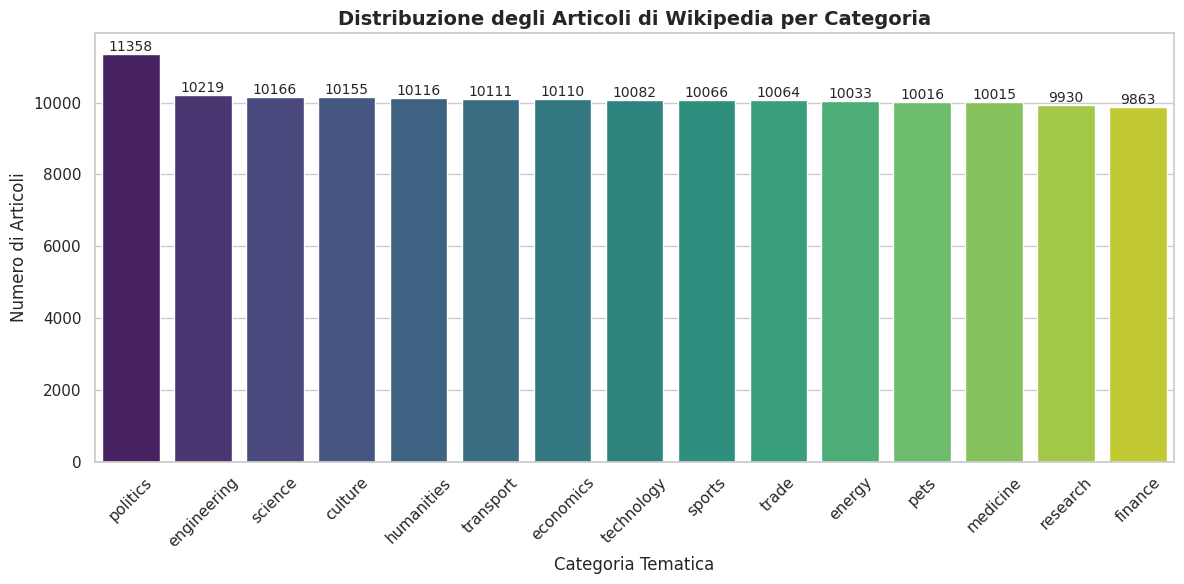

In [ ]:
# Conversione del solo riepilogo in Pandas
pdf_eda = eda_risultati.toPandas()

# Generazione del grafico con Seaborn
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=pdf_eda, x='categoria', y='num_articoli', palette='viridis')

plt.title('Distribuzione degli Articoli di Wikipedia per Categoria', fontsize=14, fontweight='bold')
plt.xlabel('Categoria Tematica', fontsize=12)
plt.ylabel('Numero di Articoli', fontsize=12)
plt.xticks(rotation=45)

# Aggiungiamo i valori sopra le barre per maggiore chiarezza
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)

plt.tight_layout()
plt.show()

La distribuzione di articoli tra le varie categorie è molto bilanciata. Questo è importante per l'addestramento del modello.

### Nuvole di parole
Generare nuvole di parole su 150.000 articoli completi in Python standard richiederebbe ore e farebbe crashare Colab. La scelta è lasciare che Spark esegua la tokenizzazione pesante, la rimozione delle stop-words e il conteggio delle frequenze in modo distribuito.

Una volta ottenuto un piccolo dataset aggregato con le 100 parole più frequenti per ogni categoria (poche righe in totale), lo scaricheremo in Pandas e useremo la libreria wordcloud per il rendering grafico.

NOTA: abbiamo aggiunto un punto 0. nel codice che rimuove una serie manuale di parole dopo aver notato visivamente la presenza frequente di parole poco significative per le categorie.

In [ ]:
# 0. Definizione preventiva della lista di stop-words estesa
default_stopwords = StopWordsRemover.loadDefaultStopWords("english")
custom_stopwords = default_stopwords + [
    "also", "one", "two", "three", "first", "many",
    "new", "used", "known", "well", "may", "part", "time"
]

# 1. Inasprimento Tokenizzazione: Solo lettere ([a-z/A-Z]) e lunghezza minima di 3 caratteri
# Questo taglia istantaneamente numeri come '000' e paroline corte prima di generare l'array
regexTokenizer = RegexTokenizer(
    inputCol="documents",
    outputCol="words",
    pattern="[^a-zA-Z]",
    minTokenLength=3
)
df_tokenized = regexTokenizer.transform(spark_df.filter("categoria IS NOT NULL AND documents IS NOT NULL"))

# 2. Rimozione delle Stopwords usando la nostra lista custom ampliata
remover = StopWordsRemover(inputCol="words", outputCol="filtered_words", stopWords=custom_stopwords)
df_filtered = remover.transform(df_tokenized)

# 3. Explode e aggregazione per Categoria
df_word_counts = df_filtered.select("categoria", F.explode("filtered_words").alias("word")) \
    .groupBy("categoria", "word") \
    .count()

# 4. Window Function: Selezioniamo solo le 100 parole più frequenti per ogni categoria
window_spec = Window.partitionBy("categoria").orderBy(F.col("count").desc())
df_top_words = df_word_counts.withColumn("rank", F.row_number().over(window_spec)) \
    .filter("rank <= 100") \
    .drop("rank")

# 5. Riduciamo il dataset a Pandas: recuperiamo solo le top parole aggregate
pdf_word_frequencies = df_top_words.toPandas()

print("Calcolo distribuito delle frequenze completato. Dati pronti per il plotting!")

Calcolo distribuito delle frequenze completato. Dati pronti per il plotting!


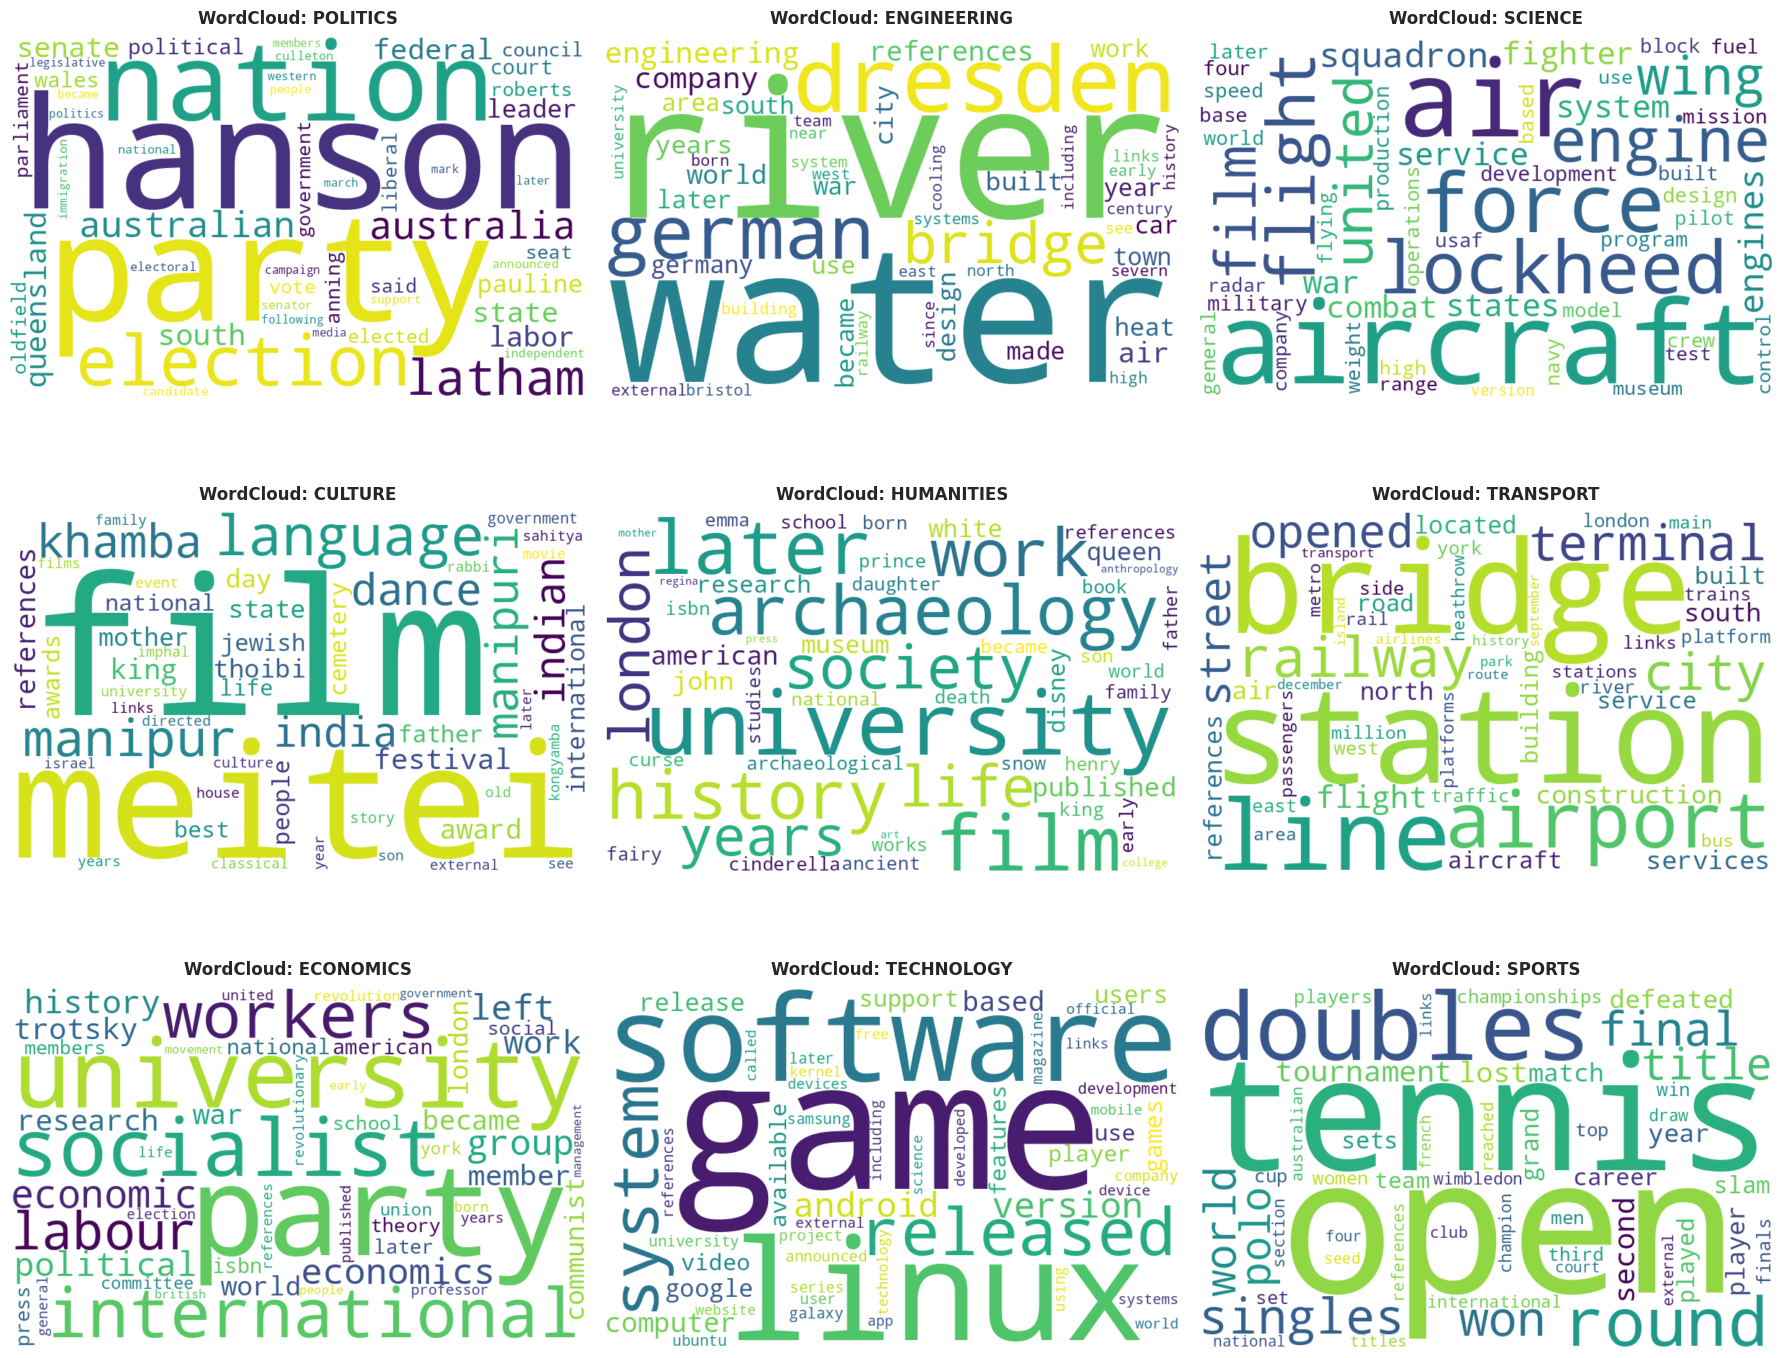

In [ ]:
# Imposta quante categorie vuoi visualizzare
N_CATEGORIE_DA_MOSTRARE = 9

# 1. Identifichiamo le top N categorie con più articoli
top_categories = eda_risultati.select("categoria").toPandas()["categoria"].values[:N_CATEGORIE_DA_MOSTRARE]

# 2. Calcolo dinamico della griglia (Impostiamo un massimo di 3 colonne per mantenere il layout pulito)
MAX_COLONNE = 3
n_complessivo = len(top_categories)
ncols = min(MAX_COLONNE, n_complessivo)
nrows = math.ceil(n_complessivo / ncols) if n_complessivo > 0 else 1

# Proporzioniamo la dimensione della figura (6 di larghezza per colonna, 5 di altezza per riga)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))

# Se c'è solo 1 grafico, matplotlib non restituisce un array. Lo forziamo a lista.
if n_complessivo == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# 3. Loop di generazione e disegno delle WordCloud
for i, cat in enumerate(top_categories):
    # Filtra le parole appartenenti alla categoria corrente
    cat_data = pdf_word_frequencies[pdf_word_frequencies['categoria'] == cat]

    # Crea il dizionario {parola: frequenza} per la WordCloud
    word_freq_dict = dict(zip(cat_data['word'], cat_data['count']))

    # Generazione della WordCloud
    wordcloud = WordCloud(
        width=800,
        height=500,
        background_color='white',
        colormap='viridis',
        max_words=50
    ).generate_from_frequencies(word_freq_dict)

    # Plotting sul relativo sotto-grafico
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f"WordCloud: {cat.upper()}", fontsize=12, fontweight='bold', pad=10)
    axes[i].axis('off')

# 4. Pulizia automatica dei sotto-grafici vuoti
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Le nuvole di parole danno una impressione immediata delle parole più frequenti per ogni categoria. Abbiamo scelto di mandare in stampa anche in forma tabellare le prime dieci parole per frequenza per ogni categoria.

In [ ]:
# 1. Utilizziamo la struttura Spark precedente filtrando solo le top 10 parole
df_top_10 = df_word_counts.withColumn("rank", F.row_number().over(window_spec)).filter("rank <= 10").orderBy("categoria", F.col("count").desc())

# 2. Convertiamo questo piccolo subset in Pandas per la visualizzazione
pdf_top_10 = df_top_10.toPandas()

# 3. Stampiamo i risultati
categories_to_print = pdf_top_10['categoria'].unique()

print("TOP 10 TERMINI PIÙ FREQUENTI PER CATEGORIA (Stop-words rimosse)\n")
print("=" * 65)

for cat in categories_to_print:
    print(f"\n CATEGORIA: {cat.upper()}")
    print("-" * 65)

    # Isola i dati della categoria corrente e ripulisce l'indice per la visualizzazione
    cat_table = pdf_top_10[pdf_top_10['categoria'] == cat][['rank', 'word', 'count']]
    cat_table.columns = ['Posizione', 'Parola', 'Conteggio']

    # Mostra la tabella senza l'indice di riga di Pandas
    print(cat_table.to_string(index=False))
    print("=" * 65)

TOP 10 TERMINI PIÙ FREQUENTI PER CATEGORIA (Stop-words rimosse)


 CATEGORIA: CULTURE
-----------------------------------------------------------------
 Posizione   Parola  Conteggio
         1     film      41597
         2   meitei      34080
         3 language      25229
         4  manipur      20903
         5   khamba      16589
         6 manipuri      15370
         7    dance      14770
         8    india      13416
         9   indian      13082
        10 festival      10845

 CATEGORIA: ECONOMICS
-----------------------------------------------------------------
 Posizione        Parola  Conteggio
         1         party      53654
         2    university      33255
         3     socialist      32716
         4 international      23210
         5       workers      21537
         6        labour      18417
         7      economic      17294
         8     economics      17153
         9         group      17098
        10          left      16536

 CATEGORIA: ENERGY
--

Accorgimenti particolari sui codici precedenti:
- L'uso di *generate_from_frequencies* (punto 3): Non abbiamo passato l'intero testo grezzo a WordCloud().generate(). Questo per delegare il calcolo massivo a Spark lasciando a Python solo il compito di "disegnare".

- La rimozione preventiva del rumore: L'uso combinato di RegexTokenizer e StopWordsRemover garantisce che nella nuvola di parole non compaiano congiunzioni o punteggiatura inutile, mostrando insight reali

Nota Architetturale: L'analisi visiva evidenzia la presenza di varianti morfologiche dello stesso lemma (es. 'History' e 'Historical'). In un ambiente di produzione industriale dotato di cluster distribuiti dedicati (es. Databricks), l'introduzione di una pipeline di Lemmatizzazione tramite il framework Spark NLP consentirebbe di ridurre ulteriormente la dimensionalità del vocabolario, ottimizzando la convergenza del modello.

Inoltre già qui possiamo vedere come alcune parole molto frequenti siano condivise da due categorie che hanno sovrapposizioni fastidiose per l'addestramento del modello (esempio univeristy in reserch e medicine)

## PIPELINE MODELLO
###Train Test Split

Possiamo ora partire ad addestrare il modello. Ripartiamo dal dataset pulito su cui facciamo la divisione train e test. Inoltre vista la dimensione del dataset e la logica di gestione delle risorse su colab abbiamo impostato una sotto selezione del 40% del dataset.

La selezione attraverso la funzione *sampleBy* permette di non avere problemi di categrie minoritarie.

In [ ]:
# 1. Pulizia e fusione immediata delle due colonne di testo
df_enriched = spark_df.filter("categoria IS NOT NULL AND documents IS NOT NULL AND summary IS NOT NULL").withColumn("text_combined", F.concat_ws(" ", F.col("summary"), F.col("documents")))

# 2. Recuperiamo le categorie per il campionamento stratificato al 30%
categorie = df_enriched.select("categoria").distinct().rdd.flatMap(lambda x: x).collect()
frazioni_dict = {cat: 0.30 for cat in categorie}

# 3. Creiamo il campione stratificato partendo dal testo unito
df_sampled = df_enriched.sampleBy("categoria", fractions=frazioni_dict, seed=42)

# 4. Eseguiamo lo split sui dati uniti
df_train_raw, df_test_raw = df_sampled.randomSplit([0.8, 0.2], seed=42)
df_train_raw.cache()

print(f"Righe di Training: {df_train_raw.count()}")
print(f"Righe di Test:     {df_test_raw.count()}")

Righe di Training: 36741
Righe di Test:     9196


## MODELLO 1: REGRESSIONE LOGISTICA
Rieffettuiamo la pulizia del testo come nella EDA, creando una pipeline che combina pulizia e peso delle parole con IDF.

In [ ]:
spark.catalog.clearCache()
gc.collect()

364

In [ ]:
# 1. Recuperiamo le stopwords di default e aggiungiamo quelle rimosse nell'EDA
default_stopwords = StopWordsRemover.loadDefaultStopWords("english")
custom_stopwords = default_stopwords + [
    "also", "one", "two", "three", "first", "many",
    "new", "used", "known", "well", "may", "part", "time"
]

# 2. Indicizzazione della Label (converte le categorie testuali in numeri: 0, 1, 2...)
label_indexer = StringIndexer(inputCol="categoria", outputCol="label")

# 3. Tokenizzazione inasprita: Solo lettere ([^a-zA-Z]) e lunghezza minima di 3 caratteri nativa
tokenizer = RegexTokenizer(
    inputCol="text_combined",
    outputCol="words",
    pattern="[^a-zA-Z]",
    minTokenLength=3
)

# 4. Rimozione Stop-Words (usando la lista estesa definita sopra)
stopwords_remover = StopWordsRemover(
    inputCol="words",
    outputCol="filtered_words",
    stopWords=custom_stopwords
)

# 5. HashingTF: Trasformiamo i token in vettori di frequenza numerica (max 10.000 feature per la RAM)
hashing_tf = HashingTF(
    inputCol="filtered_words",
    outputCol="raw_features",
    numFeatures=10000
)

# 6. IDF (Inverse Document Frequency): Pesa le parole in base alla loro rarità
idf = IDF(inputCol="raw_features", outputCol="features")

# CREAZIONE DELLA PREPROCESSING PIPELINE
# Questo blocco racchiude tutti gli stadi di trasformazione del testo
preprocessing_pipeline = Pipeline(stages=[label_indexer, tokenizer, stopwords_remover, hashing_tf, idf])

print("preprocessing_pipeline definita correttamente e blindata contro il rumore!")

preprocessing_pipeline definita correttamente e blindata contro il rumore!


In [ ]:
# Istanziamo il classificatore
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=20,
    regParam=0.05
)

# Uniamo i passaggi di preprocessing con l'algoritmo di classificazione
mod1_ml_pipeline = Pipeline(stages=[preprocessing_pipeline, lr])

Addestriamo e valutiamo il modello

In [ ]:
print("Avvio addestramento sul Train Set grezzo (calcolo feature + training modello)")
# Il fit allena l'intera catena sul train
mod1_trained = mod1_ml_pipeline.fit(df_train_raw)
print("Modello addestrato!")

print("Generazione delle predizioni sul Test Set grezzo")
# Il transform applica la stessa identica pulizia e le predizioni sul test
predictions_mod1 = mod1_trained.transform(df_test_raw)

Avvio addestramento sul Train Set grezzo (calcolo feature + training modello)
Modello addestrato!
Generazione delle predizioni sul Test Set grezzo


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

accuracy = evaluator.evaluate(predictions_mod1, {evaluator.metricName: "accuracy"})
f1_score = evaluator.evaluate(predictions_mod1, {evaluator.metricName: "f1"})

print("RISULTATI FINALI")
print("-" * 30)
print(f"Accuratezza (Accuracy): {accuracy:.2%}")
print(f"F1-Score (Weighted):   {f1_score:.2%}")
print("-" * 30)

RISULTATI FINALI
------------------------------
Accuratezza (Accuracy): 89.90%
F1-Score (Weighted):   89.85%
------------------------------


## MODELLO 2: rete neurale pyspark

Vediamo se un modello di rete neurale ci da metriche migliori senza perdere troppo in consumo di risorse. Utilizziamo un Mlp di spark dimensionato per quello che serve al nostro problema di classificazione.

In [ ]:
spark.catalog.clearCache()
gc.collect()

249

In [ ]:
# 1. Recuperiamo dinamicamente il numero di categorie dalla colonna originale del dataset grezzo
num_classes = int(df_train_raw.select("categoria").distinct().count())

print(f"Numero di categorie rilevate: {num_classes}")

# 2. Definiamo l'architettura della rete (i livelli/layers)
# Input: 10000 (le feature dell'HashingTF o VectorAssembler se usi gli N-Grams)
# Hidden 1: 64 nodi (funzione di attivazione: Sigmoide)
# Hidden 2: 32 nodi (funzione di attivazione: Sigmoide)
# Output: num_classes (funzione di attivazione: Softmax automatica)
layers = [10000, 64, 32, num_classes]

# 3. Istanziamo il MLP
mlp = MultilayerPerceptronClassifier(
    layers=layers,
    seed=42,
    maxIter=50,
    blockSize=128,
    featuresCol="features",
    labelCol="label"
)

# 4. Creiamo la nuova pipeline con il MLP
mod2_mlp_pipeline = Pipeline(stages=[label_indexer, tokenizer, stopwords_remover, hashing_tf, idf, mlp])

print("Nuova pipeline con Rete Neurale pronta per il fit!")

Numero di categorie rilevate: 15
Nuova pipeline con Rete Neurale pronta per il fit!


In [ ]:
print("Avvio addestramento sul Train Set grezzo (calcolo feature + training modello)")
# Il fit allena l'intera catena sul train
mod2_trained = mod2_mlp_pipeline.fit(df_train_raw)
print("Modello addestrato!")

print("Generazione delle predizioni sul Test Set grezzo")
# Il transform applica la stessa identica pulizia e le predizioni sul test
predictions_mod2 = mod2_trained.transform(df_test_raw)

Avvio addestramento sul Train Set grezzo (calcolo feature + training modello)
Modello addestrato!
Generazione delle predizioni sul Test Set grezzo


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

accuracy = evaluator.evaluate(predictions_mod2, {evaluator.metricName: "accuracy"})
f1_score = evaluator.evaluate(predictions_mod2, {evaluator.metricName: "f1"})

print("RISULTATI FINALI")
print("-" * 30)
print(f"Accuratezza (Accuracy): {accuracy:.2%}")
print(f"F1-Score (Weighted):   {f1_score:.2%}")
print("-" * 30)

RISULTATI FINALI
------------------------------
Accuratezza (Accuracy): 92.02%
F1-Score (Weighted):   92.00%
------------------------------


## MODELLO 3: N GRAMS
Proviamo a vedere se il modello di regressione logistica ci restituisce migliorie sostanziali utilizzando un processo di tokenizzazione n-grams. In questo caso abbiamo utilizzato Bi-Grammi in modo da mantenere più significato locale nell'analisi degli articoli.

In [ ]:
spark.catalog.clearCache()
gc.collect()

822

In [ ]:
# 1. Configurazione Stop-words (invariata)
default_stopwords = StopWordsRemover.loadDefaultStopWords("english")
custom_stopwords = default_stopwords + [
    "also", "one", "two", "three", "first", "many",
    "new", "used", "known", "well", "may", "part", "time"
]

# 2. Stadi di base: Indicizzazione e Tokenizzazione
label_indexer = StringIndexer(inputCol="categoria", outputCol="label")

tokenizer = RegexTokenizer(
    inputCol="text_combined",
    outputCol="words",
    pattern="[^a-zA-Z]",
    minTokenLength=3
)

stopwords_remover = StopWordsRemover(
    inputCol="words",
    outputCol="filtered_words",
    stopWords=custom_stopwords
)

# 3. GENERAZIONE DEI BIGRAMMI
# Prende l'array di parole pulite e crea coppie consecutive (es. "artificial", "intelligence" -> "artificial intelligence")
ngram_transformer = NGram(n=2, inputCol="filtered_words", outputCol="bigrams")

# 4. HASHING TF SEPARATI
# Dedichiamo 7.000 slot alle parole singole e 5.000 slot alle combinazioni di due parole
hashing_tf_unigrams = HashingTF(inputCol="filtered_words", outputCol="tf_unigrams", numFeatures=7000)
hashing_tf_bigrams = HashingTF(inputCol="bigrams", outputCol="tf_bigrams", numFeatures=5000)

# 5. VECTOR ASSEMBLER: Uniamo i due vettori in un unico grande vettore da 12.000 feature
assembler = VectorAssembler(
    inputCols=["tf_unigrams", "tf_bigrams"],
    outputCol="raw_features"
)

# 6. IDF: Calcola il peso finale sull'intero vettore combinato
idf = IDF(inputCol="raw_features", outputCol="features")

# 7. Modello di Logistic Regression
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=20,
    regParam=0.05
)

# PIPELINE
mod3_ml_pipeline = Pipeline(stages=[
    label_indexer,
    tokenizer,
    stopwords_remover,
    ngram_transformer,
    hashing_tf_unigrams,
    hashing_tf_bigrams,
    assembler,
    idf,
    lr
])

print("Pipeline Ibrida (Unigrams + Bigrams) configurata con successo")

Pipeline Ibrida (Unigrams + Bigrams) configurata con successo


In [ ]:
print("Avvio addestramento sul Train Set grezzo (calcolo feature + training modello)")
# Il fit allena l'intera catena sul train
mod3_trained = mod3_ml_pipeline.fit(df_train_raw)
print("Modello addestrato!")

print("Generazione delle predizioni sul Test Set grezzo")
# Il transform applica la stessa identica pulizia e le predizioni sul test
predictions_mod3 = mod3_trained.transform(df_test_raw)

Avvio addestramento sul Train Set grezzo (calcolo feature + training modello)
Modello addestrato!
Generazione delle predizioni sul Test Set grezzo


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

accuracy = evaluator.evaluate(predictions_mod3, {evaluator.metricName: "accuracy"})
f1_score = evaluator.evaluate(predictions_mod3, {evaluator.metricName: "f1"})

print("RISULTATI FINALI")
print("-" * 30)
print(f"Accuratezza (Accuracy): {accuracy:.2%}")
print(f"F1-Score (Weighted):   {f1_score:.2%}")
print("-" * 30)

RISULTATI FINALI
------------------------------
Accuratezza (Accuracy): 90.39%
F1-Score (Weighted):   90.37%
------------------------------


## SELEZIONE MODELLO

Le meteriche complessive di tutti e tre i modelli sono estremamente buone, con accuracy e F1-score sopra l'89.9%, e anche in termini di consumo di risorse non risultano essere modelli pesanti. Il modello 2 con rete neurale ha metriche leggermente migliori.

Studiamo più nel dettaglio il classification report per vedere margini e potenzialita di questo modello.

In [ ]:
spark.catalog.clearCache()
gc.collect()

104

In [ ]:
# 1. Recuperiamo i nomi reali delle categorie dallo StringIndexer (primo stadio della pipeline)
nomi_categorie = mod2_trained.stages[0].labels

# 2. Portiamo in Pandas solo le colonne 'label' e 'prediction' del Test Set
pdf_predictions = predictions_mod2.select("label", "prediction").toPandas()

# 3. Stampiamo il report dettagliato classe per classe
print("ANALISI DELLE PERFORMANCE PER CATEGORIA (MODELLO 2-RETE NEURALE)\n")
print(classification_report(
    pdf_predictions["label"],
    pdf_predictions["prediction"],
    target_names=nomi_categorie
))

ANALISI DELLE PERFORMANCE PER CATEGORIA (MODELLO 2-RETE NEURALE)

              precision    recall  f1-score   support

    politics       0.99      1.00      0.99       651
   transport       0.93      0.96      0.94       583
   economics       0.92      0.94      0.93       643
      energy       0.94      0.96      0.95       600
      sports       0.96      0.97      0.96       619
  technology       0.94      0.95      0.94       609
    medicine       0.78      0.77      0.77       593
 engineering       0.90      0.88      0.89       617
       trade       0.95      0.94      0.94       613
     culture       0.96      0.96      0.96       612
    research       0.80      0.79      0.79       622
     science       0.93      0.93      0.93       587
  humanities       0.92      0.92      0.92       624
        pets       0.99      0.97      0.98       617
     finance       0.88      0.87      0.88       606

    accuracy                           0.92      9196
   macro avg  


 Generazione della Matrice di Confusione


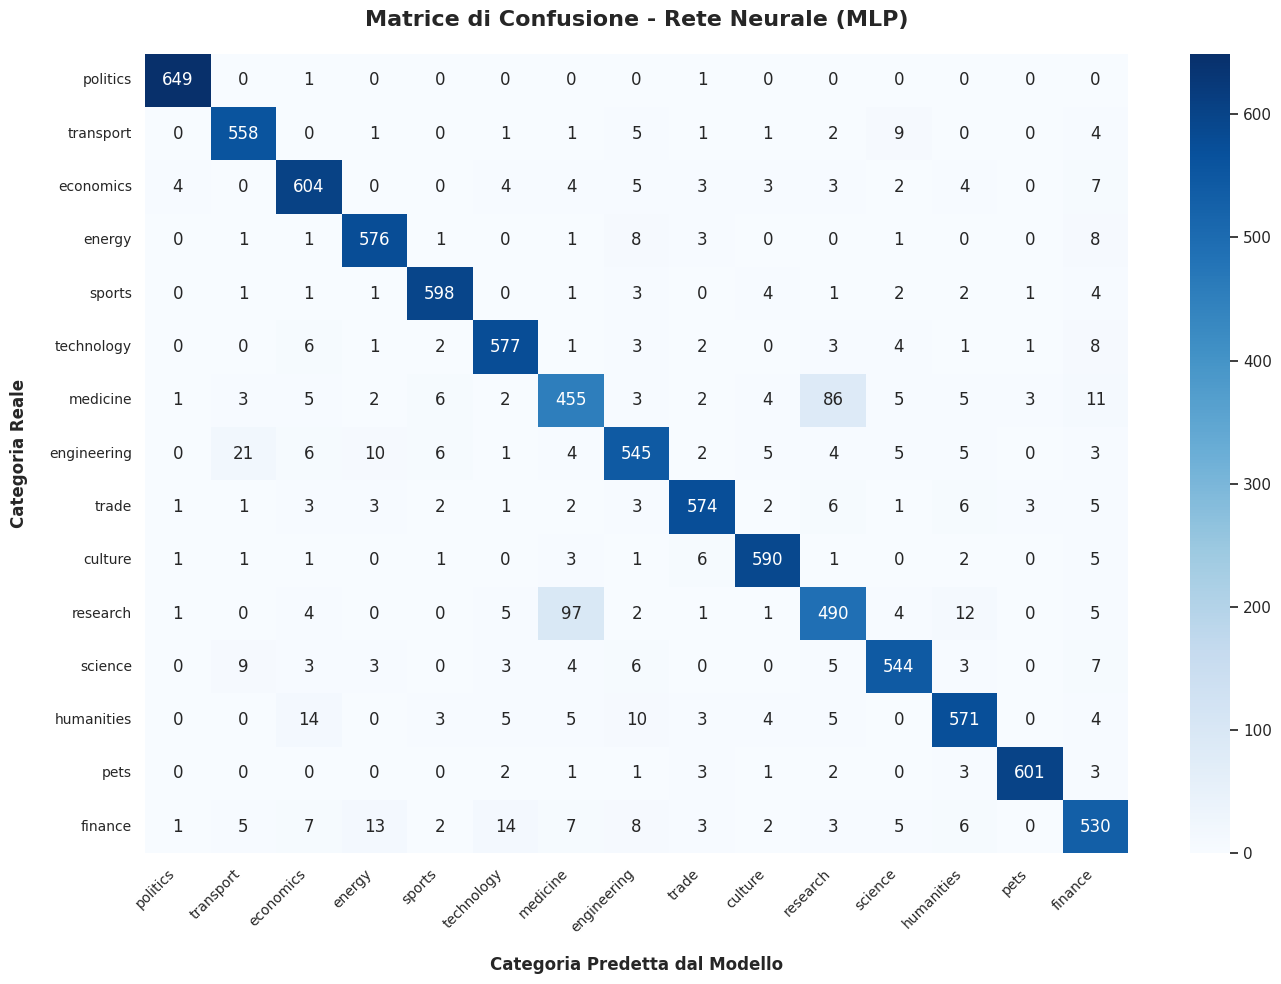

In [ ]:
print("\n Generazione della Matrice di Confusione")

cm = confusion_matrix(
    pdf_predictions["label"],
    pdf_predictions["prediction"],
    labels=list(range(len(nomi_categorie)))
)

plt.figure(figsize=(14, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nomi_categorie, # Traduce l'indice numerico nel nome della categoria sull'asse X
    yticklabels=nomi_categorie  # Traduce l'indice numerico nel nome della categoria sull'asse Y
)

plt.title("Matrice di Confusione - Rete Neurale (MLP)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Categoria Predetta dal Modello", fontsize=12, fontweight='bold', labelpad=15)
plt.ylabel("Categoria Reale", fontsize=12, fontweight='bold', labelpad=15)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

### ANALISI METRICHE MODELLO 2
Le metriche sono molto positive. Su alcune classi estremamente caratteristiche il modello ha metriche eccezionali (politics, sports, pets). Si vede bene però che su alcune categorie faccia fatica ad ottenere gli stessi risultati per sovrapposizione con altre categorie. In particolare medicine ha un f1-score del 78%, particolarmente insoddisfacente. Questo è dovuto ad una sovrapposizione della categoria con research che anche ha metriche inferiori.

## VISUALIZZAZIONE PREVISIONI

Facciamo una schema visivo delle previsioni del modello 2 sul test set, in modo da vedere alcuni esempi di buono o cattivo comportamento del modello.

In [ ]:
# 1. Usiamo il decoder nativo di Spark che legge i metadati da mod2_trained
converter = IndexToString(
    inputCol="prediction",
    outputCol="label_predetta",
    labels=mod2_trained.stages[0].labels
)

# 2. Applichiamo la trasformazione per iniettare la colonna testuale decodificata nel DataFrame predictions
df_con_nomi = converter.transform(predictions_mod2)

# 3. Estraiamo i 10 esempi
esempi_test = df_con_nomi.select("documents", "categoria", "label_predetta").limit(10).collect()

print("VERIFICA VISIVA (10 ESEMPI DAL TEST SET - RETE NEURALE)\n")
print("=" * 85)

for idx, row in enumerate(esempi_test, 1):
    testo_originale = row["documents"]

    # Puliamo l'input da eventuali spazi fantasma
    label_reale = row["categoria"].strip()
    label_predetta = row["label_predetta"].strip()

    # Confronto stringa-stringa sicuro
    status = "✅ CORRETTO" if label_reale == label_predetta else "❌ ERRORE"

    # Tronchiamo il testo a 250 caratteri per la leggibilità nel notebook
    testo_estratto = testo_originale[:250].replace("\n", " ") + "..." if len(testo_originale) > 250 else testo_originale

    print(f"ESEMPIO #{idx}")
    print(f"Testo (Inizio): \"{testo_estratto}\"")
    print(f"Categoria Reale:  {label_reale}")
    print(f"Predizione Rete:   {label_predetta} ({status})")
    print("=" * 85)

VERIFICA VISIVA (10 ESEMPI DAL TEST SET - RETE NEURALE)

ESEMPIO #1
Testo (Inizio): "humanities are academic disciplines that study aspects of human society and culture. in the renaissance, the term contrasted with divinity and referred to what is now called classics, the main area of secular study in universities at the time. today,..."
Categoria Reale:  humanities
Predizione Rete:   humanities (✅ CORRETTO)
ESEMPIO #2
Testo (Inizio): "technology is the application of knowledge for achieving practical goals in a reproducible way. the word technology can also mean the products resulting from such efforts,: 117 including both tangible tools such as utensils or machines, and intangibl..."
Categoria Reale:  technology
Predizione Rete:   technology (✅ CORRETTO)
ESEMPIO #3
Testo (Inizio): "== africa business summit developments. == africa is home to over 1 billion people and has 54 countries with its largest economies being nigeria, south africa, egypt, nairobi among others. however, the eco

## Salvataggio e ricarica modello

  Per applicazioni future abbiamo scelto di salvare il modello selezionato e renderlo ricaricaricabile senza dover ripassare dall'addestramento.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1. Definiamo il percorso all'interno di Google Drive
percorso_drive = "/content/drive/MyDrive/BigData/wikipedia_mlp_pipeline"

print("Salvataggio in corso della Pipeline e della Rete Neurale su Google Drive")

# 2. Salviamo l'intero modello composto (Preprocessing + Rete Neurale)
mod2_trained.write().overwrite().save(percorso_drive)

print(f"Il modello è al sicuro su Drive nella cartella: {percorso_drive}")

Salvataggio in corso della Pipeline e della Rete Neurale su Google Drive
Il modello è al sicuro su Drive nella cartella: /content/drive/MyDrive/BigData/wikipedia_mlp_pipeline


In [ ]:
# Definiamo lo stesso percorso dove abbiamo salvato il modello
percorso_drive = "/content/drive/MyDrive/BigData/wikipedia_mlp_pipeline"

print("Caricamento del modello da Google Drive")

# Carichiamo il modello
mod2_ricaricato = PipelineModel.load(percorso_drive)

print("Modello ricaricato con successo e pronto!")

Caricamento del modello da Google Drive
Modello ricaricato con successo e pronto!


# CONCLUSIONI

Il progetto sviluppato ha dato risultati molto soddisfacenti. Una accuracy del 92% su un problema di classificazione su testi lunghi e con 15 categorie è da ritenersi molto buono. Sicuramente la ottima distribuzione delle categorie del dataset ha dato forza al classificatore.

Il modello a rete neurale ha mostrato ottime capacità nel determinare perimetri non lineari tra le diverse categorie, senza avere costi computazionali troppo alti. Sulle categorie più defintie ha metriche del 99% che mostrano una grande stabilità, ma anche le categorie che hanno metriche inferiori sono legate ad una effettiva vicinanza o sovrapposizione del linguaggio del testo umano piuttosto che ad un problema strutturale del modello.

Inoltre è interessante anche che il modello 3 con la regressione logistica sui Bi-grammi ha metriche confrontabili con il MLP e cresiciute rispetto al modello 1; questo ci indica che una analisi delle feature approfondita può migliorare ulteriormente i risultati della regressione logistica ed ottenere risultati assolutamente paragonabili ad una rete neurale.

Abbiamo cercato durante tutto il processo di utilizzare il linguaggio sql e spark per ottimizzare al meglio la gestione della RAM e poter di conseguenza rendere il progetto applicabile anche a dataset di maggiori dimensioni.